# Notebook 5 – Bivariate Analysis

### 1. What Is Bivariate Analysis?

Bivariate analysis is the process of studying two variables together to understand whether a relationship or pattern exists between them.

It helps us understand how one variable changes in relation to another.

### 2. Types of Relationships

#### A. Numerical vs Numerical

This examines the relationship between two numerical variables.

**Examples:**

* Age vs Salary
* Income vs Spending
* Tenure vs Monthly Charges
* Monthly Charges vs Total Charges

**Techniques:**

* Scatter Plot
* Correlation Coefficient

#### B. Numerical vs Categorical

This compares a numerical variable across different categories.

**Examples:**

* Department vs Salary
* Contract Type vs Monthly Charges
* Churn Status vs Tenure

**Techniques:**

* Box Plot
* Violin Plot
* Grouped Summary Statistics

#### C. Categorical vs Categorical

This examines how two categorical variables are distributed together.

**Examples:**

* Product Category vs Sales Category
* Contract Type vs Churn
* Internet Service vs Churn

**Techniques:**

* Cross Tabulation
* Grouped Bar Chart

### 3. Important Techniques

| Technique         | Purpose                                                                                   |
| ----------------- | ----------------------------------------------------------------------------------------- |
| Scatter Plot      | Displays the relationship between two numerical variables.                                |
| Correlation       | Measures the strength and direction of a linear relationship between numerical variables. |
| Box Plot          | Compares the distribution of numerical values across categories.                          |
| Violin Plot       | Shows the distribution and density of numerical values across categories.                 |
| Grouped Bar Chart | Compares categories across groups.                                                        |
| Cross Tabulation  | Counts combinations of categories in two categorical variables.                           |

### 4. Interpreting Relationships

* **Positive relationship:** One variable tends to increase as the other increases.
* **Negative relationship:** One variable tends to decrease as the other increases.
* **Weak relationship:** The variables show little linear association.
* **No clear relationship:** No obvious pattern is visible.
* **Group differences:** Numerical values differ across categories.
* **Category association:** The distribution of one category varies across another category.

### 5. Why Is Bivariate Analysis Important in AI/ML?

Bivariate analysis helps identify relationships between features, discover potential predictors, understand differences between groups, and support feature selection.

However, **correlation does not prove causation**. A relationship between two variables does not necessarily mean that one causes the other.


### Real-World Example: Understanding Customer Churn

A telecommunications company wants to understand which customer characteristics are associated with churn.

We will investigate three types of relationships.

### 1. Numerical vs Numerical

**Example: Tenure vs Total Charges**

Tenure indicates how many months a customer has stayed with the company. Total Charges indicates the total amount charged to that customer.

A scatter plot helps us observe whether total charges tend to increase with tenure.

If the points generally move upward from left to right, this suggests a positive relationship.

However, monthly charges and differences in customer plans may also influence this pattern.

### 2. Numerical vs Categorical

**Example: Churn vs Tenure**

We compare customer tenure between customers who left and customers who stayed.

A box plot or violin plot helps us examine differences in their tenure distributions.

If customers who left generally have shorter tenures, this suggests that churn is associated with shorter customer relationships in this dataset.

We must inspect the actual chart before drawing a conclusion.

### 3. Categorical vs Categorical

**Example: Contract vs Churn**

We compare contract types with churn status.

A cross-tabulation table counts customers in each combination. A grouped bar chart makes the differences easier to see.

We can also calculate churn percentages within each contract type to compare groups fairly.

### How We Interpret the Results

* A scatter plot reveals the direction and pattern of a numerical relationship.
* A correlation coefficient summarizes the strength and direction of a linear relationship.
* Box plots and violin plots reveal differences in numerical distributions across categories.
* Cross-tabulation shows how frequently categorical combinations occur.
* Within-group percentages help compare categories of different sizes.

**Important:** The examples describe what to investigate. The final conclusions must be based on the actual results from our dataset.


Seaborn is not installed. Violin plots will be skipped.
1. NUMERICAL VS NUMERICAL

Relationship: tenure vs TotalCharges
Correlation: 0.826
Finding: Strong positive linear relationship.


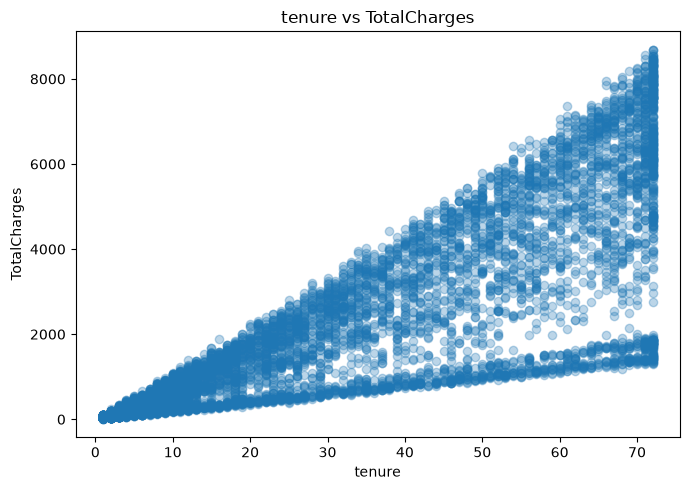


Relationship: MonthlyCharges vs TotalCharges
Correlation: 0.651
Finding: Moderate positive linear relationship.


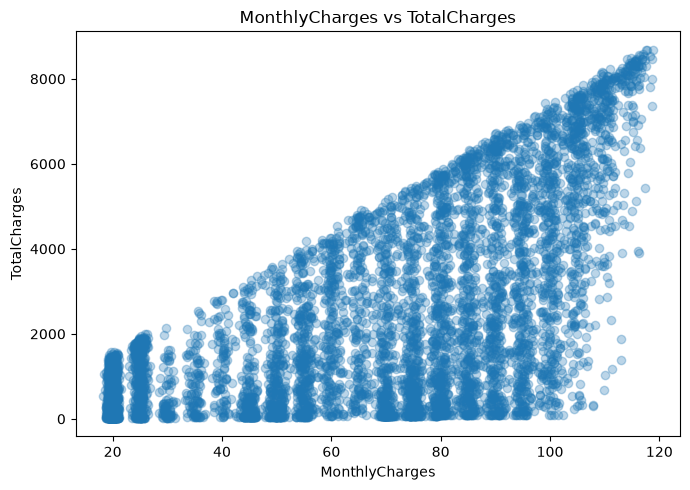


2. NUMERICAL VS CATEGORICAL

Tenure Statistics by Churn Status:


,count,mean,median,min,max,std
Churn,,,,,,
No,5174,37.57,38.0,0,72,24.11
Yes,1869,17.98,10.0,1,72,19.53



Findings:
Median tenure for customers who left: 10.0
Median tenure for customers who stayed: 38.0
Customers who left have a lower median tenure in this dataset.


<Figure size 700x500 with 0 Axes>

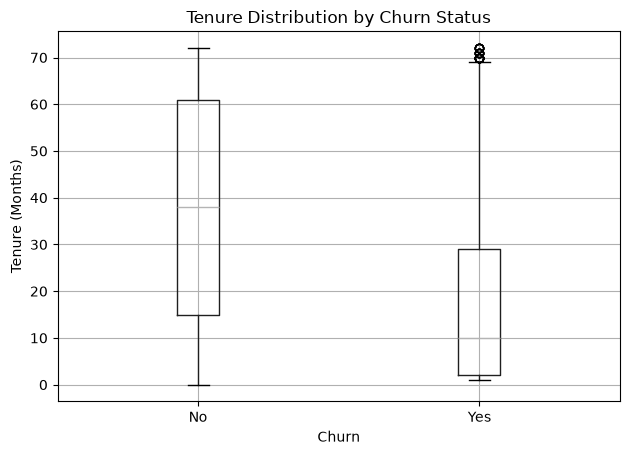

Install seaborn to generate the violin plot.

3. CATEGORICAL VS CATEGORICAL

Cross Tabulation: Contract vs Churn


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48



Churn Percentage Within Each Contract Type:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


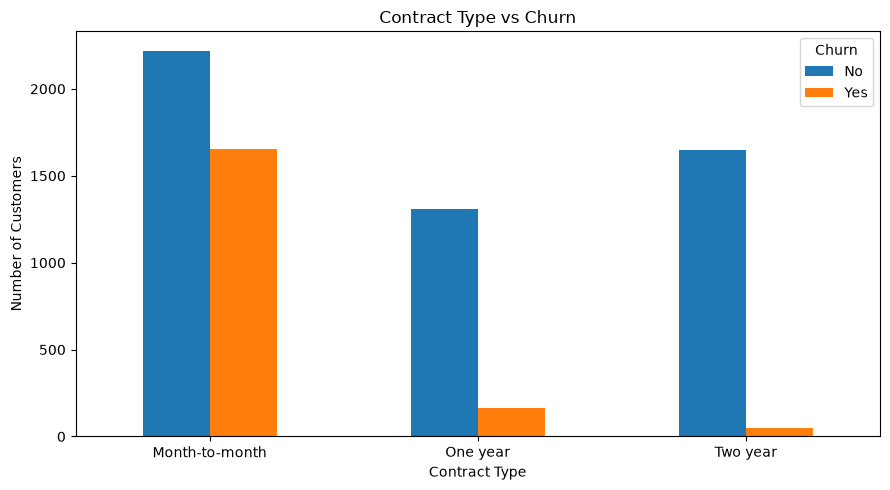


Findings:
Month-to-month: 42.71% of customers in this contract group left.
One year: 11.27% of customers in this contract group left.
Two year: 2.83% of customers in this contract group left.

FINAL SUMMARY
Dataset dimensions: (7043, 21)
Bivariate analysis completed for numerical-numerical, numerical-categorical, and categorical-categorical variables.
Review the charts, correlation values, group statistics, and churn percentages before documenting your conclusions.


In [1]:
# Step 3: Implement Concept - Bivariate Analysis

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Import seaborn for violin plots
try:
    import seaborn as sns
except ImportError:
    sns = None
    print("Seaborn is not installed. Violin plots will be skipped.")

# Load the dataset
file_path = Path("dataset/Telco-Customer-Churn.csv")
df = pd.read_csv(file_path)

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# ==================================================
# 1. NUMERICAL VS NUMERICAL
# ==================================================

print("=" * 60)
print("1. NUMERICAL VS NUMERICAL")
print("=" * 60)

numerical_pairs = [
    ("tenure", "TotalCharges"),
    ("MonthlyCharges", "TotalCharges")
]

for x_column, y_column in numerical_pairs:

    data = df[[x_column, y_column]].dropna()

    # Calculate correlation
    correlation = data[x_column].corr(data[y_column])

    print(f"\nRelationship: {x_column} vs {y_column}")
    print("Correlation:", round(correlation, 3))

    # Interpret the correlation
    if correlation >= 0.7:
        print("Finding: Strong positive linear relationship.")
    elif correlation >= 0.3:
        print("Finding: Moderate positive linear relationship.")
    elif correlation > 0:
        print("Finding: Weak positive linear relationship.")
    elif correlation <= -0.7:
        print("Finding: Strong negative linear relationship.")
    elif correlation <= -0.3:
        print("Finding: Moderate negative linear relationship.")
    elif correlation < 0:
        print("Finding: Weak negative linear relationship.")
    else:
        print("Finding: No linear correlation.")

    # Scatter plot
    plt.figure(figsize=(7, 5))
    plt.scatter(data[x_column], data[y_column], alpha=0.3)
    plt.title(f"{x_column} vs {y_column}")
    plt.xlabel(x_column)
    plt.ylabel(y_column)
    plt.tight_layout()
    plt.show()


# ==================================================
# 2. NUMERICAL VS CATEGORICAL
# ==================================================

print("\n" + "=" * 60)
print("2. NUMERICAL VS CATEGORICAL")
print("=" * 60)

numerical_column = "tenure"
categorical_column = "Churn"

data = df[[numerical_column, categorical_column]].dropna()

# Grouped summary statistics
group_summary = data.groupby(categorical_column)[
    numerical_column
].agg(["count", "mean", "median", "min", "max", "std"])

print("\nTenure Statistics by Churn Status:")
display(group_summary.round(2))

# Compare median tenure
group_medians = data.groupby(categorical_column)[
    numerical_column
].median()

print("\nFindings:")
if "Yes" in group_medians.index and "No" in group_medians.index:
    churn_median = group_medians["Yes"]
    stayed_median = group_medians["No"]

    print("Median tenure for customers who left:", churn_median)
    print("Median tenure for customers who stayed:", stayed_median)

    if churn_median < stayed_median:
        print(
            "Customers who left have a lower median tenure "
            "in this dataset."
        )
    elif churn_median > stayed_median:
        print(
            "Customers who left have a higher median tenure "
            "in this dataset."
        )
    else:
        print("Both groups have the same median tenure.")

# Box plot
plt.figure(figsize=(7, 5))
df.boxplot(column=numerical_column, by=categorical_column)
plt.title("Tenure Distribution by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

# Violin plot
if sns is not None:
    plt.figure(figsize=(7, 5))
    sns.violinplot(
        data=data,
        x=categorical_column,
        y=numerical_column
    )
    plt.title("Tenure Distribution by Churn Status")
    plt.xlabel("Churn")
    plt.ylabel("Tenure (Months)")
    plt.tight_layout()
    plt.show()
else:
    print("Install seaborn to generate the violin plot.")


# ==================================================
# 3. CATEGORICAL VS CATEGORICAL
# ==================================================

print("\n" + "=" * 60)
print("3. CATEGORICAL VS CATEGORICAL")
print("=" * 60)

first_category = "Contract"
second_category = "Churn"

data = df[[first_category, second_category]].dropna()

# Cross-tabulation
cross_table = pd.crosstab(
    data[first_category],
    data[second_category]
)

print("\nCross Tabulation: Contract vs Churn")
display(cross_table)

# Row-wise percentage distribution
cross_percentage = pd.crosstab(
    data[first_category],
    data[second_category],
    normalize="index"
) * 100

print("\nChurn Percentage Within Each Contract Type:")
display(cross_percentage.round(2))

# Grouped bar chart using counts
cross_table.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

# Interpret churn percentages
print("\nFindings:")
if "Yes" in cross_percentage.columns:
    for contract_type, row in cross_percentage.iterrows():
        churn_percentage = row["Yes"]
        print(
            f"{contract_type}: {churn_percentage:.2f}% "
            "of customers in this contract group left."
        )

# ==================================================
# 4. FINAL SUMMARY
# ==================================================

print("\n" + "=" * 60)
print("FINAL SUMMARY")
print("=" * 60)

print("Dataset dimensions:", df.shape)
print(
    "Bivariate analysis completed for numerical-numerical, "
    "numerical-categorical, and categorical-categorical variables."
)
print(
    "Review the charts, correlation values, group statistics, "
    "and churn percentages before documenting your conclusions."
)